In [1]:
import pandas as pd
import numpy as np

In [2]:
df=pd.read_csv(r"D:\PROJECT\Customer_Churn_Prediction_System\data\Telco-Customer-Churn.csv")

In [2]:
df = pd.read_csv(r"D:\PROJECT\Customer_Churn_Prediction_System\data\Telco-Customer-Churn.csv")

In [3]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print(df.shape)
print(df.columns)
df.info()

(7043, 21)
Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str   

In [5]:
print(df.isnull().sum())

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64


In [6]:
print(df.duplicated().sum())

0


In [7]:
print(df["Churn"].value_counts())
print(df["Churn"].value_counts(normalize=True)*100)

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Churn
No     73.463013
Yes    26.536987
Name: proportion, dtype: float64


In [8]:
df_clean=df.copy()

In [9]:
df_clean['TotalCharges']=pd.to_numeric(df['TotalCharges'],errors="coerce")

In [10]:
df_clean=df_clean.dropna(subset=["TotalCharges"])

In [11]:
df_clean=df_clean.drop("customerID",axis=1)

In [12]:
print(df_clean.shape)

(7032, 20)


In [ ]:
##Exploratpry Data Analysis(EDA)

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

In [14]:
print(df_clean["Churn"].value_counts())

Churn
No     5163
Yes    1869
Name: count, dtype: int64


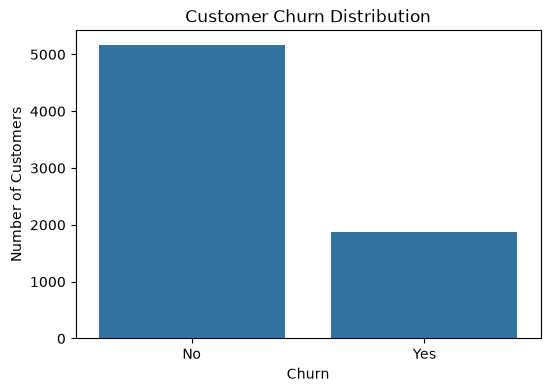

In [17]:
plt.figure(figsize=(6,4))
sns.countplot(data=df_clean,x="Churn")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.show()

In [18]:
churn_percentage=df_clean["Churn"].value_counts(normalize=True)*100
print(churn_percentage)

Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


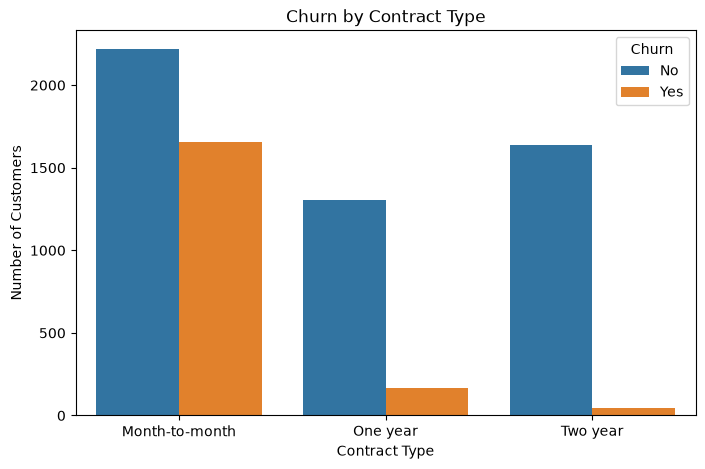

In [19]:
##Churn vs Contract
plt.figure(figsize=(8,5))

sns.countplot(data=df_clean,x="Contract",hue="Churn")
plt.title("Churn by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

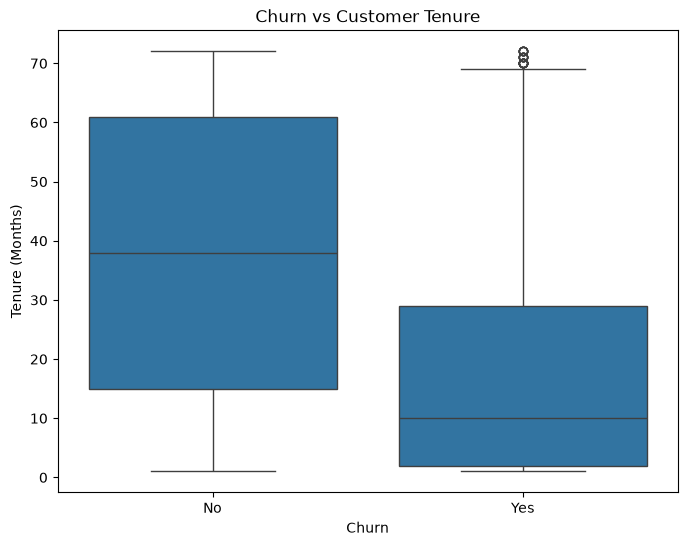

In [20]:
##Churn vs tenure
plt.figure(figsize=(8,6))

sns.boxplot(data=df_clean,x="Churn",y="tenure")
plt.title("Churn vs Customer Tenure")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

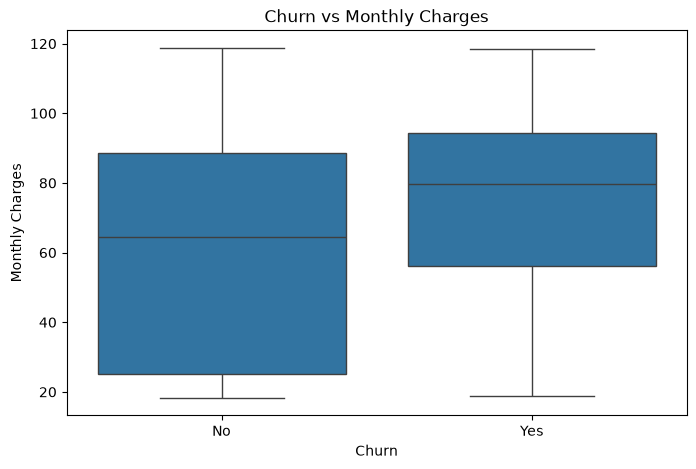

In [21]:
##Churn vs MonthlyCharges
plt.figure(figsize=(8,5))
sns.boxplot(data=df_clean,x="Churn",y="MonthlyCharges")
plt.title("Churn vs Monthly Charges")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

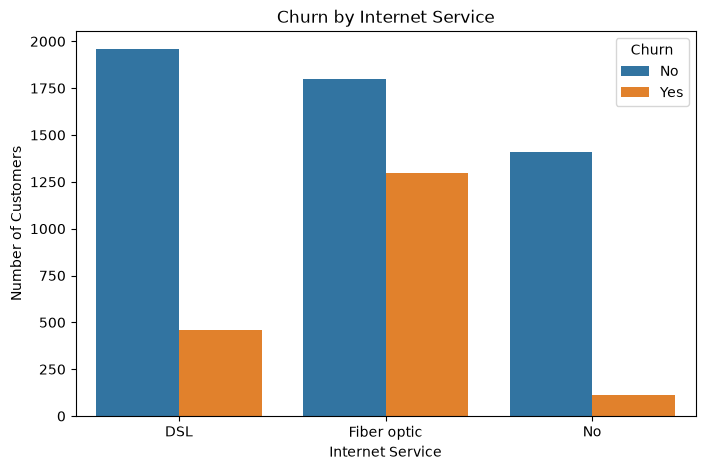

In [22]:
##Churn vs InternetServices
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean,x="InternetService",hue="Churn")
plt.title("Churn by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

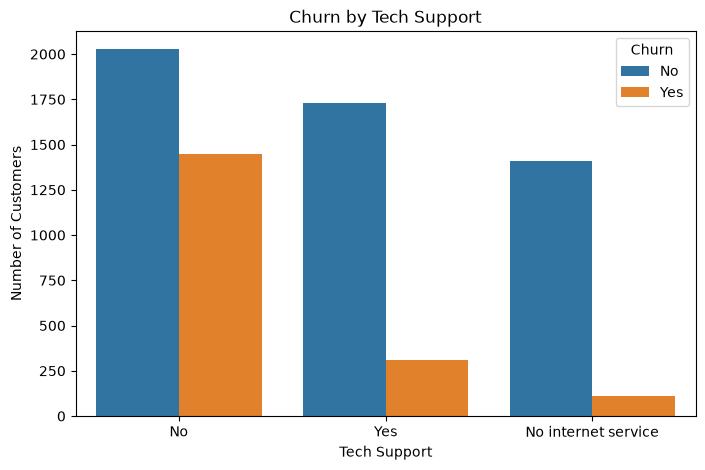

In [23]:
##Churn vs TechSupport
plt.figure(figsize=(8, 5))

sns.countplot(data=df_clean,x="TechSupport",hue="Churn")
plt.title("Churn by Tech Support")
plt.xlabel("Tech Support")
plt.ylabel("Number of Customers")
plt.show()

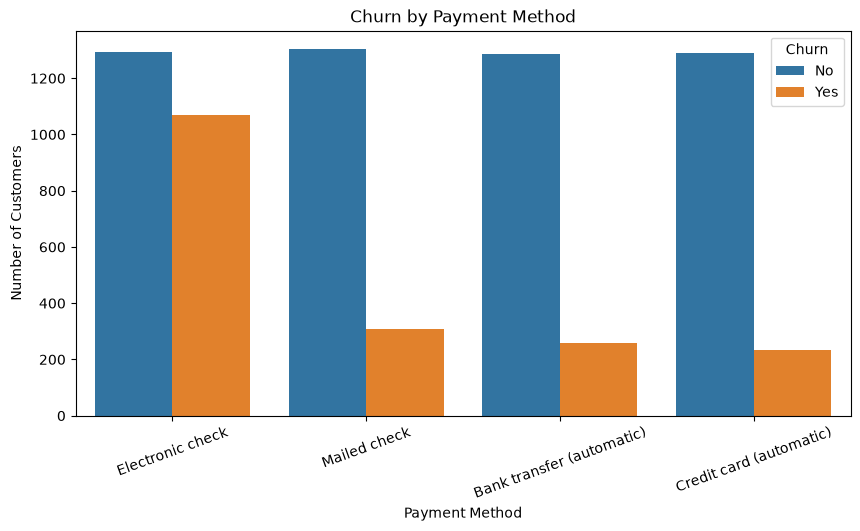

In [24]:
##churn vs PaymentMethod
plt.figure(figsize=(10, 5))

sns.countplot(data=df,x="PaymentMethod",hue="Churn")
plt.title("Churn by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=20)
plt.show()